In [1]:
from collections import Counter
from imblearn.over_sampling import SMOTE, RandomOverSampler
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

import sys

import pandas as pd
import numpy as np
import math

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

from sklearn.decomposition import PCA

from IPython.display import display
from ipywidgets import interact

from scipy.spatial import Voronoi
from scipy.spatial import QhullError

sys.path.append("../../../")

from utils.build_scaler import build_scaler

In [2]:
paths = [
    "../../../data/processed/X_train.csv",
    "../../../data/processed/X_test.csv",
    "../../../data/processed/y_train.csv",
    "../../../data/processed/y_test.csv",
]

X_train = pd.read_csv(paths[0])
X_test = pd.read_csv(paths[1])

y_train = pd.read_csv(paths[2])
y_test = pd.read_csv(paths[3])

if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "X_train e X_test precisam ter as mesmas colunas, na mesma ordem."
    )

if list(y_train.columns) != list(y_test.columns):
    raise ValueError(
        "y_train e y_test precisam ter as mesmas colunas, na mesma ordem."
    )

print(f"X Treino: {X_train.shape}")
print(f"X Teste:  {X_test.shape}")
display(X_train.head())

print(f"Y Treino: {y_train.shape}")
print(f"Y Teste:  {y_test.shape}")
display(y_train.head())

X Treino: (10648, 24)
X Teste:  (4564, 24)


,GENDER,WBC,NE#,LY#,MO#,EO#,BA#,RBC,HGB,HCT,...,PLT,MPV,PCT,PDW,SD,SDTSD,TSD,FERRITTE,FOLATE,B12
0,0,6.04,3.57,1.87,0.52,0.04,0.04,4.95,11.56,38.33,...,238.1,10.07,0.24,19.52,28.80,438.60,6.566347,8.09,10.63,212.1
1,0,5.59,3.30,1.77,0.38,0.08,0.06,4.82,14.81,41.26,...,237.6,7.91,0.19,18.83,89.87,320.67,28.025696,47.39,11.69,420.8
2,0,5.96,3.27,1.87,0.62,0.16,0.04,4.65,13.90,41.30,...,188.0,10.80,0.20,11.90,47.00,332.00,14.156627,34.34,20.00,312.4
3,1,7.15,3.88,2.52,0.44,0.25,0.06,4.88,14.70,43.60,...,254.0,9.80,0.25,11.10,95.71,329.01,29.090301,55.01,7.02,149.1
4,0,10.75,6.38,3.09,1.06,0.20,0.02,4.18,12.20,34.20,...,207.0,10.10,0.21,9.30,71.99,304.99,23.604053,206.40,8.99,755.9


Y Treino: (10648, 1)
Y Teste:  (4564, 1)


,All_Class
0,2
1,0
2,0
3,0
4,0


In [3]:
model = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=2005
)

scalers = build_scaler(model)

results = {}

for name, pipeline in scalers.items():

    pipeline.fit(X_train)

    clusters = pipeline.predict(X_test)

    results[name] = clusters

In [4]:
def smote_mrs(X, y, R=5, ratio=0.20, k_max=3, random_state=2005):
    X_arr, y_arr = np.asarray(X), np.asarray(y)
    grupos = KMeans(n_clusters=R, n_init=10, random_state=random_state).fit_predict(X_arr)

    Xs, ys, resumo = [], [], []
    for g in np.unique(grupos):
        Xg, yg = X_arr[grupos == g], y_arr[grupos == g]
        antes = pd.Series(yg).value_counts()
        n_sint = n_dup = 0

        if len(antes) >= 2:
            alvo = int(ratio * antes.max())
            precisa = {c: alvo for c, n in antes.items() if n < alvo}

            com_vizinhos = {c: a for c, a in precisa.items() if antes[c] >= 2}
            if com_vizinhos:
                k = max(1, min(k_max, min(antes[c] for c in com_vizinhos) - 1))
                Xg, yg = SMOTE(sampling_strategy=com_vizinhos, k_neighbors=k,
                               random_state=random_state).fit_resample(Xg, yg)
                n_sint = len(yg) - antes.sum()

            depois = pd.Series(yg).value_counts()
            faltam = {c: alvo for c in precisa if depois[c] < alvo}
            if faltam:
                tam = len(yg)
                Xg, yg = RandomOverSampler(sampling_strategy=faltam,
                                           random_state=random_state).fit_resample(Xg, yg)
                n_dup = len(yg) - tam

        Xs.append(Xg); ys.append(yg)
        resumo.append({"Grupo": g, "Originais": int(antes.sum()),
                       "Sintéticos (SMOTE)": int(n_sint), "Duplicados (ROS)": int(n_dup)})

    return np.vstack(Xs), np.concatenate(ys), pd.DataFrame(resumo)

In [5]:
R = 5
RATIO = 0.20

y_tr = y_train.squeeze()
bin_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]

scalers_base, results_base = scalers, dict(results)

scalers = build_scaler(KMeans(n_clusters=5, n_init=10, random_state=2005))
results = {}
mrs_data = {}

for name, pipeline in scalers.items():
    scaler = pipeline.named_steps["scaler"]
    pipeline.steps[-1] = ("model", clone(pipeline.named_steps["model"]))

    Xs_train = scaler.fit_transform(X_train)

    X_mrs, y_mrs, resumo = smote_mrs(Xs_train, y_tr, R=R, ratio=RATIO)
    X_mrs = pd.DataFrame(X_mrs, columns=Xs_train.columns)

    for c in bin_cols:
        vals = np.unique(Xs_train[c])
        X_mrs[c] = vals[np.abs(X_mrs[c].values[:, None] - vals[None, :]).argmin(axis=1)]

    pipeline.named_steps["model"].fit(X_mrs)
    results[name] = pipeline.predict(X_test)
    mrs_data[name] = {"X": X_mrs, "y": y_mrs, "resumo": resumo}

    sint = resumo["Sintéticos (SMOTE)"].sum() + resumo["Duplicados (ROS)"].sum()
    print(f"[{name:9s}] treino {len(X_train)} -> {len(X_mrs)} linhas "
          f"({sint / len(X_mrs):.1%} artificiais) | { {int(k): v for k, v in sorted(Counter(y_mrs).items())} }")


[standard ] treino 10648 -> 15080 linhas (29.4% artificiais) | {0: 6770, 1: 1911, 2: 3509, 3: 1296, 4: 1594}
[minmax   ] treino 10648 -> 14108 linhas (24.5% artificiais) | {0: 6770, 1: 1508, 2: 3071, 3: 1251, 4: 1508}
[robust   ] treino 10648 -> 15277 linhas (30.3% artificiais) | {0: 6770, 1: 1704, 2: 3646, 3: 1579, 4: 1578}
[quantile ] treino 10648 -> 15600 linhas (31.7% artificiais) | {0: 6770, 1: 1832, 2: 3704, 3: 1647, 4: 1647}


In [6]:
def metricas(scalers_d, results_d, cenario):
    linhas = []
    for name, pipe in scalers_d.items():
        cl = results_d[name]
        Xt = pipe[:-1].transform(X_test)
        linhas.append({
            "Cenário": cenario, "Scaler": name,
            "ARI": adjusted_rand_score(y_test.squeeze(), cl),
            "NMI": normalized_mutual_info_score(y_test.squeeze(), cl),
            "Silhouette": silhouette_score(Xt, cl),
            "Davies-Bouldin": davies_bouldin_score(Xt, cl),
        })
    return pd.DataFrame(linhas)

comparacao = pd.concat([metricas(scalers_base, results_base, "Sem SMOTE"),
                        metricas(scalers, results, "SMOTE-MRS")])
display(comparacao.sort_values(["Scaler", "Cenário"]).reset_index(drop=True)
        .style.format({"ARI": "{:.4f}", "NMI": "{:.4f}", "Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}"}))

,Cenário,Scaler,ARI,NMI,Silhouette,Davies-Bouldin
0,SMOTE-MRS,minmax,0.0780,0.0752,0.2052,1.7267
1,Sem SMOTE,minmax,0.0861,0.0816,0.2096,1.7051
2,SMOTE-MRS,quantile,0.1541,0.1865,0.0973,2.3882
3,Sem SMOTE,quantile,0.1636,0.2207,0.1089,2.2155
4,SMOTE-MRS,robust,0.2918,0.1894,0.1170,2.0383
5,Sem SMOTE,robust,0.2506,0.2205,0.1012,1.9775
6,SMOTE-MRS,standard,0.2140,0.2154,0.0863,2.4566
7,Sem SMOTE,standard,0.2159,0.2187,0.0938,2.2333


In [7]:
for name, d in mrs_data.items():
    print(f"\n== {name} ==")
    display(d["resumo"])


== standard ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS)
0,0,1288,67,0
1,1,2064,1546,0
2,2,1939,534,0
3,3,4139,2143,0
4,4,1218,142,0



== minmax ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS)
0,0,2166,555,0
1,1,1809,245,256
2,2,3639,1529,0
3,3,1243,311,0
4,4,1791,564,0



== robust ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS)
0,0,1461,155,0
1,1,4030,2244,783
2,2,14,0,0
3,3,3006,611,0
4,4,2137,836,0



== quantile ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS)
0,0,1301,145,0
1,1,2543,1770,0
2,2,2448,976,0
3,3,2145,1529,0
4,4,2211,532,0


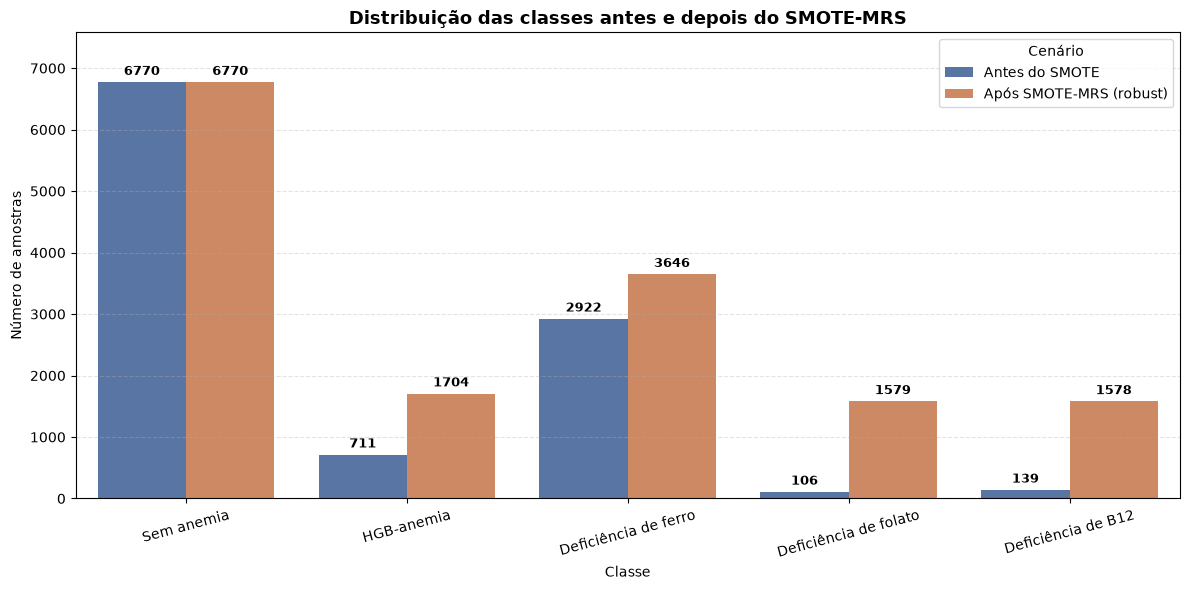

In [8]:
nomes_classes = {
    0: "Sem anemia",
    1: "HGB-anemia",
    2: "Deficiência de ferro",
    3: "Deficiência de folato",
    4: "Deficiência de B12",
}

nome_scaler = "robust"

orig_counts = pd.Series(y_tr).value_counts().sort_index()
smote_counts = pd.Series(mrs_data[nome_scaler]["y"]).value_counts().sort_index()

contagem_original = pd.DataFrame({
    "Classe": orig_counts.index.map(nomes_classes),
    "Quantidade": orig_counts.values,
    "Cenário": "Antes do SMOTE",
})

contagem_smote = pd.DataFrame({
    "Classe": smote_counts.index.map(nomes_classes),
    "Quantidade": smote_counts.values,
    "Cenário": f"Após SMOTE-MRS ({nome_scaler})",
})

distribuicao = pd.concat([contagem_original, contagem_smote], ignore_index=True)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=distribuicao,
    x="Classe",
    y="Quantidade",
    hue="Cenário",
    palette=["#4C72B0", "#DD8452"],
)

# Adiciona os números exatos em cima de cada barra
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9.5, fontweight="bold")

plt.title("Distribuição das classes antes e depois do SMOTE-MRS", fontsize=13, fontweight="bold")
plt.xlabel("Classe")
plt.ylabel("Número de amostras")
plt.ylim(0, distribuicao["Quantidade"].max() * 1.12)
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

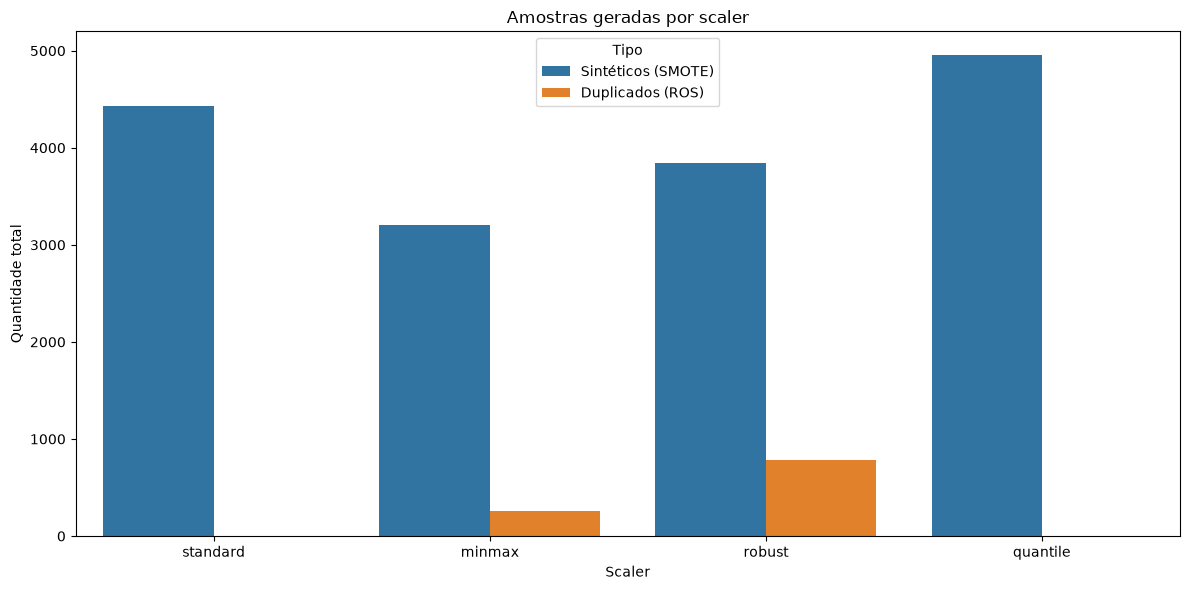

In [9]:
resumos = []

for scaler_name, dados in mrs_data.items():
    resumo = dados["resumo"].copy()
    resumo["Scaler"] = scaler_name
    resumos.append(resumo)

resumos = pd.concat(resumos, ignore_index=True)

resumos_long = resumos.melt(
    id_vars=["Scaler", "Grupo"],
    value_vars=["Sintéticos (SMOTE)", "Duplicados (ROS)"],
    var_name="Tipo",
    value_name="Quantidade"
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=resumos_long,
    x="Scaler",
    y="Quantidade",
    hue="Tipo",
    estimator="sum",
    errorbar=None
)

plt.title("Amostras geradas por scaler")
plt.xlabel("Scaler")
plt.ylabel("Quantidade total")
plt.tight_layout()
plt.show()

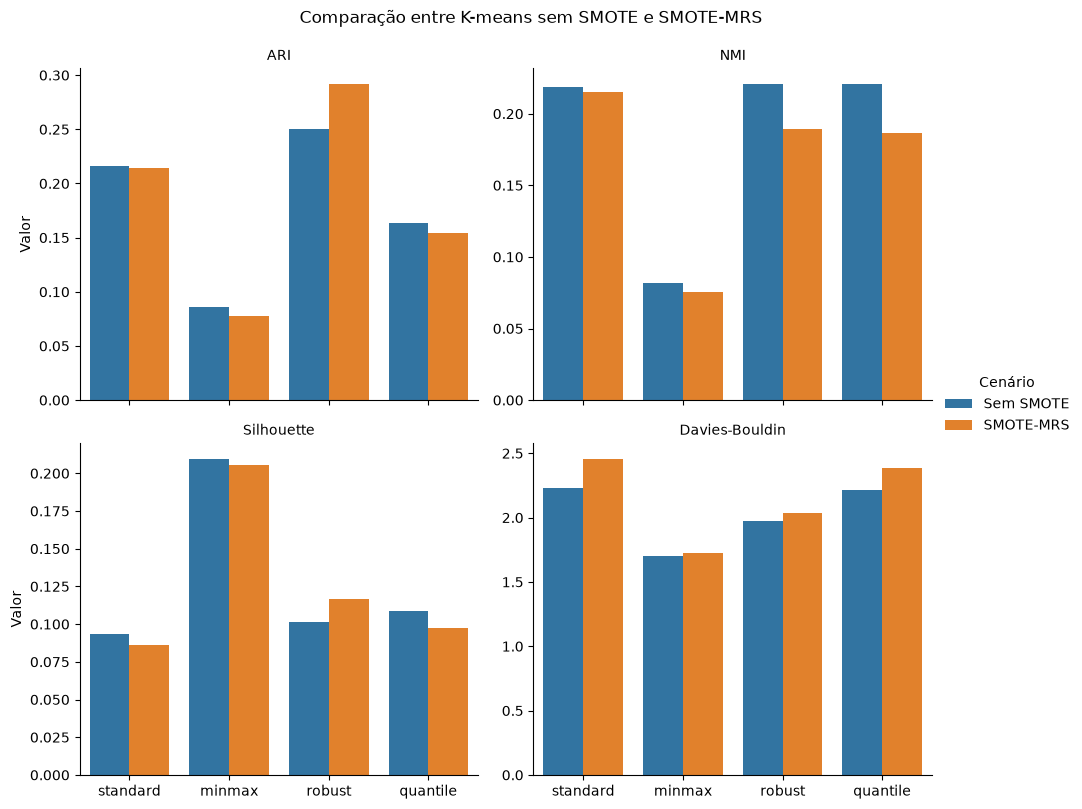

In [10]:
metricas_plot = comparacao.melt(
    id_vars=["Cenário", "Scaler"],
    value_vars=["ARI", "NMI", "Silhouette", "Davies-Bouldin"],
    var_name="Métrica",
    value_name="Valor"
)

g = sns.catplot(
    data=metricas_plot,
    x="Scaler",
    y="Valor",
    hue="Cenário",
    col="Métrica",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.2,
    sharey=False
)

g.set_titles("{col_name}")
g.set_axis_labels("", "Valor")
g.fig.suptitle("Comparação entre K-means sem SMOTE e SMOTE-MRS", y=1.03)
plt.show()

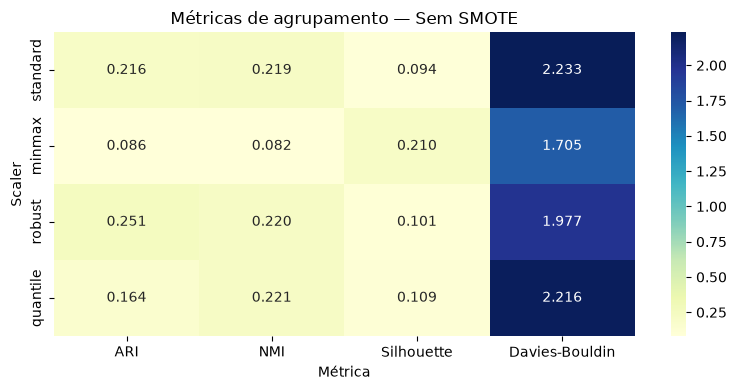

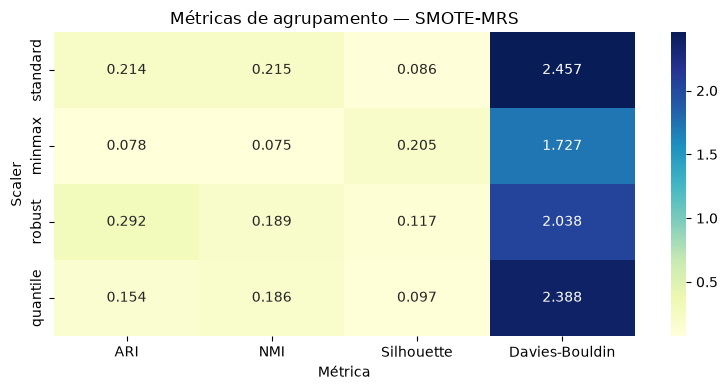

In [11]:
for cenario in comparacao["Cenário"].unique():
    tabela = (
        comparacao[comparacao["Cenário"] == cenario]
        .set_index("Scaler")[[
            "ARI", "NMI", "Silhouette", "Davies-Bouldin"
        ]]
    )

    plt.figure(figsize=(8, 4))
    sns.heatmap(
        tabela,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu"
    )

    plt.title(f"Métricas de agrupamento — {cenario}")
    plt.xlabel("Métrica")
    plt.ylabel("Scaler")
    plt.tight_layout()
    plt.show()

In [12]:
import ipywidgets as widgets
from sklearn.decomposition import PCA

def atualizar_pca(nome_scaler):
    pipeline = scalers[nome_scaler]
    X_test_transformado = pipeline[:-1].transform(X_test)
    clusters_test = results[nome_scaler]

    pca = PCA(n_components=2, random_state=42)
    X_test_pca = pca.fit_transform(X_test_transformado)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.scatterplot(
        x=X_test_pca[:, 0],
        y=X_test_pca[:, 1],
        hue=clusters_test,
        palette="tab10",
        s=30,
        alpha=0.65,
        ax=axes[0],
    )
    axes[0].set_title(f"K-means: clusters encontrados ({nome_scaler})")
    axes[0].set_xlabel("Componente principal 1")
    axes[0].set_ylabel("Componente principal 2")

    sns.scatterplot(
        x=X_test_pca[:, 0],
        y=X_test_pca[:, 1],
        hue=y_test.squeeze(),
        palette="tab10",
        s=30,
        alpha=0.65,
        ax=axes[1],
    )
    axes[1].set_title("Classes clínicas verdadeiras")
    axes[1].set_xlabel("Componente principal 1")
    axes[1].set_ylabel("Componente principal 2")

    plt.tight_layout()
    plt.show()

widgets.interact(
    atualizar_pca,
    nome_scaler=widgets.Dropdown(
        options=list(scalers.keys()),
        value="robust" if "robust" in scalers else list(scalers.keys())[0],
        description="Scaler:",
    ),
);

interactive(children=(Dropdown(description='Scaler:', index=2, options=('standard', 'minmax', 'robust', 'quant…

In [13]:
nomes_classes = {
    0: "Sem anemia",
    1: "HGB-anemia",
    2: "Deficiência de ferro",
    3: "Deficiência de folato",
    4: "Deficiência de B12",
}

def atualizar_heatmap(nome_scaler):
    clusters_test = results[nome_scaler]

    tabela_clusters = pd.crosstab(
        pd.Series(clusters_test, name="Cluster"),
        pd.Series(y_test.squeeze(), name="Classe real"),
        normalize="index"
    )

    tabela_clusters.columns = [
        nomes_classes.get(c, str(c))
        for c in tabela_clusters.columns
    ]

    plt.figure(figsize=(10, 5))
    sns.heatmap(
        tabela_clusters,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    plt.title(f"Proporção de classes clínicas em cada cluster ({nome_scaler})")
    plt.xlabel("Classe clínica")
    plt.ylabel("Cluster")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

widgets.interact(
    atualizar_heatmap,
    nome_scaler=widgets.Dropdown(
        options=list(results.keys()),
        value="robust" if "robust" in results else list(results.keys())[0],
        description="Scaler:",
    ),
);


interactive(children=(Dropdown(description='Scaler:', index=2, options=('standard', 'minmax', 'robust', 'quant…